# Analiza: Aktywność fizyczna a dolegliwości kręgosłupa w ciąży
> Wskaźnik aktywności fizycznej: **minuty aktywności na tydzień** (freq_mid × dur_mid)


Podział na grupy wg normy WHO: ≥150 min/tydz. umiarkowanej aktywności.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.rcParams.update({'font.family': 'DejaVu Sans',
                     'axes.spines.top': False, 'axes.spines.right': False,
                    'axes.grid': True, 'grid.alpha': 0.3, 'grid.linestyle': '--'})



## 1. Wczytanie i przygotowanie danych

In [2]:
df = pd.read_csv("dane_ciaza.CSV")

col_map = {
    '1. Który to trymestr?': 'trymestr',
    '2. Która to ciąża?': 'ktora_ciaza',
    '3. Czy ciąża przebiega fizjologicznie? ': 'fizjologiczna',
    '1. Czy przed ciążą była Pani regularnie aktywna fizycznie?': 'aktywna_przed',
    '2. Czy w trakcie ciąży podejmuje Pani aktywność fizyczną?': 'aktywna_w_ciazy',
    '3. Jak często wykonuje Pani aktywność fizyczną w ciągu tygodnia?': 'czestotliwosc',
    '4. Jak długo przeciętnie trwa jedna sesja aktywności fizycznej? ': 'dlugosc_sesji',
    '5. Jakie formy aktywności fizycznej Pani wykonuje? (można zaznaczyć kilka)': 'formy_af',
    '1. Czy przed ciążą odczuwała Pani bóle kręgosłupa?': 'bol_kregoslupa_przed',
    '2. Czy w czasie ciąży odczuwa Pani bóle kręgosłupa?': 'bol_kregoslupa_ciaza',
    '1. W którym odcinku kręgosłupa ból występuje najczęściej? (można zaznaczyć kilka)': 'odcinek_bolu',
    '2. Jak często występują dolegliwości bólowe?': 'czestotliwosc_bolu',
    '3. Jak ból wpływa na codzienne funkcjonowanie? (0 - brak wpływu, 5 - bardzo duży wpływ) ': 'wplyw_bolu',
    '1. Czy przed ciążą odczuwała Pani ból w obrębie obręczy biodrowej?': 'bol_biodra_przed',
    '2. Czy w trakcie ciąży odczuwa Pani ból w obrębie obręczy biodrowej?': 'bol_biodra_ciaza',
    '3. Jak silny jest ból w skali VAS (0 - brak bólu, 10 - najsilniejszy możliwy ból) ': 'VAS',
    '2. Jak ocenia Pani komfort chodzenia w czasie ciąży? \n(0 - bardzo niski, 5 - bardzo wysoki)': 'komfort_chodzenia',
    '1. Jaki charakter ma Pani praca?': 'charakter_pracy',
}
df = df.rename(columns=col_map)

df['wzrost'] = df['2. Wysokość ciała'].astype(str).str.extract(r'(\d+)').astype(float)
df['masa_przed'] = pd.to_numeric(
    df['3. Masa ciała przed ciążą'].astype(str).str.extract(r'(\d+[\.,]?\d*)')[0].str.replace(',','.'), errors='coerce')
df['masa_teraz'] = pd.to_numeric(
    df['4. Aktualna masa ciała '].astype(str).str.extract(r'(\d+[\.,]?\d*)')[0].str.replace(',','.'), errors='coerce')
df['przyrost_masy'] = df['masa_teraz'] - df['masa_przed']
df['data_ur'] = pd.to_datetime(df['1. Data urodzenia'], errors='coerce')
df['wiek'] = ((pd.Timestamp('2026-01-01') - df['data_ur']).dt.days / 365.25).round(1)
df['BMI_przed'] = (df['masa_przed'] / (df['wzrost']/100)**2).round(1)
df['VAS'] = pd.to_numeric(df['VAS'], errors='coerce')
df['aktywna_bin'] = df['aktywna_w_ciazy'].map({'Tak': 1, 'Nie': 0})

all_cols = df.columns.tolist()
rmdq_start = all_cols.index('1. Z powodu bólu pleców większość dnia spędzam w domu.')
rmdq_cols = all_cols[rmdq_start: rmdq_start + 24]
for c in rmdq_cols:
    df[c] = df[c].map({'Tak': 1, 'Nie': 0})
df['RMDQ'] = df[rmdq_cols].sum(axis=1)

df.head(3)


,Sygnatura czasowa,1. Data urodzenia,2. Wysokość ciała,3. Masa ciała przed ciążą,4. Aktualna masa ciała,5. Wykonywany zawód,charakter_pracy,"2. Czy Pani praca wiąże się z dźwiganiem, schylaniem się lub długotrwałym przebywaniem w jednej pozycji?",3. Ile godzin dziennie Pani pracuje?,trymestr,...,5. Czy trudności w chodzeniu wpływają na wykonywanie codziennych czynności?,wzrost,masa_przed,masa_teraz,przyrost_masy,data_ur,wiek,BMI_przed,aktywna_bin,RMDQ
0,2026/01/23 2:59:42 PM EET,2001-05-12,175,65,72,Fakturzystka,Siedząca,Tak,6-8 godzin,II (14. tydzień - 27. tydzień),...,Nie,175.0,65.0,72.0,7.0,2001-05-12,24.6,21.2,1,2.0
1,2026/01/23 3:16:06 PM EET,1990-07-13,167,59,71,Mama,Mieszana (siedząco-stojąca),Tak,>8 godzin,I (1. tydzień - 13. tydzień),...,W niewielkim stopniu,167.0,59.0,71.0,12.0,1990-07-13,35.5,21.2,0,19.0
2,2026/01/23 4:17:45 PM EET,1997-03-17,164,48,54,Pielęgniarka,Fizyczna,Tak,>8 godzin,II (14. tydzień - 27. tydzień),...,W umiarkowanym stopniu,164.0,48.0,54.0,6.0,1997-03-17,28.8,17.8,1,13.0


## 2. Wskaźnik aktywności fizycznej — minuty/tydzień

Wskaźnik obliczany jest jako iloczyn środka przedziału częstotliwości
i środka przedziału czasu trwania sesji:

| Przedział częstotliwości | Środek (freq_mid) |
|---|---|
| 1–2 razy/tydz. | 1,5 |
| 3–4 razy/tydz. | 3,5 |
| ≥5 razy/tydz.  | 5,5 |

| Czas trwania sesji | Środek (dur_mid) |
|---|---|
| <30 min | 20 min |
| 30–60 min | 45 min |
| >60 min | 75 min |

**min_tydz = freq_mid × dur_mid** (0 dla kobiet nieaktywnych)

Norma WHO dla ciężarnych: ≥150 min/tydz.

In [3]:
freq_mid = {'1-2 razy': 1.5, '3-4 razy': 3.5, '≥5 razy': 5.5}
dur_mid  = {'<30 minut': 20.0, '30-60 minut': 45.0, '>60 minut': 75.0}

df['freq_mid'] = df['czestotliwosc'].map(freq_mid).fillna(0)
df['dur_mid']  = df['dlugosc_sesji'].map(dur_mid).fillna(0)

# Nieaktywne = 0 niezależnie od wypełnionych pól
df['min_tydz'] = df.apply(
    lambda r: 0.0 if r['aktywna_bin'] == 0 else r['freq_mid'] * r['dur_mid'],
    axis=1
)

df['who_group'] = df['min_tydz'].apply(
    lambda x: 'Nieaktywna (0)' if x == 0
    else ('Niska aktywność (<150)' if x < 150
    else 'Norma WHO (≥150)')
)

print("Rozkład min_tydz:")
print(df['min_tydz'].describe().round(2))
print("\nGrupy:")
print(df['who_group'].value_counts())


Rozkład min_tydz:
count     46.00
mean     102.93
std      101.62
min        0.00
25%        7.50
50%       70.00
75%      157.50
max      412.50
Name: min_tydz, dtype: float64

Grupy:
who_group
Niska aktywność (<150)    18
Norma WHO (≥150)          16
Nieaktywna (0)            12
Name: count, dtype: int64


## 3. Statystyki opisowe

In [4]:
n = len(df)
print(f"n = {n}")
desc_vars = ['wiek', 'wzrost', 'masa_przed', 'BMI_przed', 'przyrost_masy', 'min_tydz', 'RMDQ', 'VAS']
print(df[desc_vars].describe().round(2))


n = 46
        wiek  wzrost  masa_przed  BMI_przed  przyrost_masy  min_tydz   RMDQ  \
count  46.00   46.00       46.00      46.00          46.00     46.00  46.00   
mean   29.69  166.76       63.39      22.78           8.38    102.93   6.76   
std     4.01    6.91       10.40       3.36           5.71    101.62   7.21   
min    21.70  151.00       47.00      17.30          -9.00      0.00   0.00   
25%    27.42  163.25       56.25      20.45           4.00      7.50   0.00   
50%    29.60  165.50       63.00      22.20           8.00     70.00   4.00   
75%    31.20  172.75       69.00      24.70          12.00    157.50  13.00   
max    40.70  183.00       89.00      30.40          22.00    412.50  21.00   

         VAS  
count  19.00  
mean    5.26  
std     2.02  
min     2.00  
25%     4.00  
50%     5.00  
75%     6.00  
max     9.00  


## 4. Wykresy 



### Rys. 1 — Rozkład trymestrów

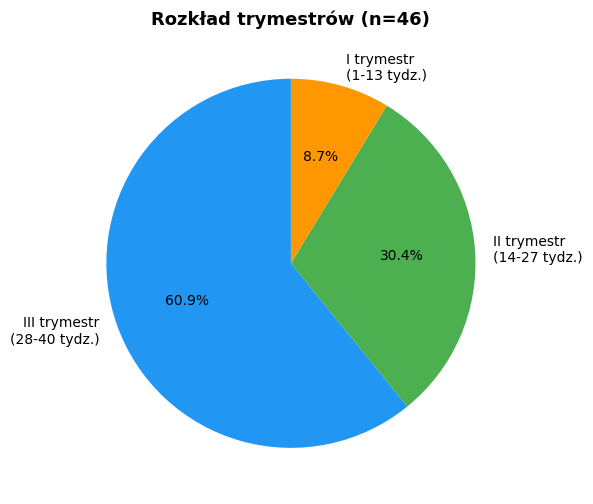

In [6]:
fig, ax = plt.subplots(figsize=(6,6))
trim_counts = df['trymestr'].value_counts()
trim_labels = ['III trymestr\n(28-40 tydz.)', 'II trymestr\n(14-27 tydz.)', 'I trymestr\n(1-13 tydz.)']
trim_colors = ['#2196F3', '#4CAF50', '#FF9800']
ax.pie(trim_counts.values, labels=trim_labels, colors=trim_colors,
       autopct='%1.1f%%', startangle=90)
ax.set_title('Rozkład trymestrów (n=46)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig01_trymestr.png', dpi=150, bbox_inches='tight')
plt.show()



### Rys. 2 — Kolejność ciąży

In [ ]:
fig, ax = plt.subplots(figsize=(7,5))
ciaza_counts = df['ktora_ciaza'].value_counts()
ax.bar(range(len(ciaza_counts)), ciaza_counts.values, color='#5C6BC0')
ax.set_xticks(range(len(ciaza_counts)))
ax.set_xticklabels(ciaza_counts.index, rotation=10, ha='right')
ax.set_ylabel('Liczba kobiet', fontsize=12)
ax.set_title('Kolejność ciąży', fontsize=13, fontweight='bold')
for i, v in enumerate(ciaza_counts.values):
    ax.text(i, v+0.3, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('fig02_ktora_ciaza.png', dpi=150, bbox_inches='tight')
plt.show()


### Rys. 3 — Charakter pracy zawodowej

In [ ]:
fig, ax = plt.subplots(figsize=(7,5))
praca_counts = df['charakter_pracy'].value_counts()
ax.barh(praca_counts.index, praca_counts.values, color='#26A69A')
ax.set_xlabel('Liczba kobiet', fontsize=12)
ax.set_title('Charakter pracy zawodowej', fontsize=13, fontweight='bold')
for i, v in enumerate(praca_counts.values):
    ax.text(v+0.1, i, str(v), va='center', fontweight='bold')
plt.tight_layout()
plt.savefig('fig03_praca.png', dpi=150, bbox_inches='tight')
plt.show()


### Rys. 4 — Aktywność przed i w ciąży

In [ ]:
fig, ax = plt.subplots(figsize=(7,5))
grupy = ['Przed ciążą', 'W trakcie ciąży']
tak_n = [(df['aktywna_przed']=='Tak').sum(), (df['aktywna_w_ciazy']=='Tak').sum()]
nie_n = [(df['aktywna_przed']=='Nie').sum(), (df['aktywna_w_ciazy']=='Nie').sum()]
x = np.arange(len(grupy)); w = 0.35
b1 = ax.bar(x-w/2, tak_n, w, label='Tak', color='#4CAF50')
b2 = ax.bar(x+w/2, nie_n, w, label='Nie', color='#F44336')
ax.set_xticks(x); ax.set_xticklabels(grupy)
ax.set_ylabel('Liczba kobiet', fontsize=12)
ax.set_title('Aktywność fizyczna przed i w ciąży', fontsize=13, fontweight='bold')
ax.legend()
for xi, (t, ni) in zip(x, zip(tak_n, nie_n)):
    ax.text(xi-w/2, t+0.2, str(t), ha='center', fontweight='bold')
    ax.text(xi+w/2, ni+0.2, str(ni), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('fig04_aktywnosc.png', dpi=150, bbox_inches='tight')
plt.show()


### Rys. 5 — Częstotliwość i formy aktywności fizycznej

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
czest = df[df['aktywna_bin']==1]['czestotliwosc'].value_counts()
order = ['1-2 razy', '3-4 razy', '\u22655 razy']
czest = czest.reindex([o for o in order if o in czest.index])
axes[0].bar(czest.index, czest.values, color='#42A5F5')
axes[0].set_ylabel('Liczba kobiet'); axes[0].set_title('Częstotliwość AF w tygodniu', fontweight='bold')
for i, v in enumerate(czest.values):
    axes[0].text(i, v+0.2, str(int(v)), ha='center', fontweight='bold')

formy = df['formy_af'].dropna().str.split(';').explode().str.strip().value_counts().head(7)
axes[1].barh(formy.index[::-1], formy.values[::-1], color='#AB47BC')
axes[1].set_xlabel('Liczba wskazań'); axes[1].set_title('Formy aktywności fizycznej', fontweight='bold')
for i, v in enumerate(formy.values[::-1]):
    axes[1].text(v+0.1, i, str(v), va='center')
plt.tight_layout()
plt.savefig('fig05_formy_af.png', dpi=150, bbox_inches='tight')
plt.show()


### Rys. 6 — Histogram rozkładu wskaźnika min/tydz.

In [ ]:
BLUE='#1a6e8e'; TEAL='#2aaa8a'; GRAY='#888888'
colors3 = [GRAY, TEAL, BLUE]
g0 = df[df['min_tydz']==0]
g1 = df[(df['min_tydz']>0)&(df['min_tydz']<150)]
g2 = df[df['min_tydz']>=150]
groups = [g0, g1, g2]
group_labels = ['Nieaktywna\n(n=12)', 'Niska <150 min\n(n=18)', 'Norma WHO \u226515\n(n=16)']
kw_stat, kw_p = stats.kruskal(g0['RMDQ'], g1['RMDQ'], g2['RMDQ'])
r_rmdq, p_rmdq = stats.spearmanr(df['min_tydz'], df['RMDQ'])
mask = df['VAS'].notna()
r_vas, p_vas = stats.spearmanr(df.loc[mask,'min_tydz'], df.loc[mask,'VAS'])
m_fit, b_fit = np.polyfit(df['min_tydz'], df['RMDQ'], 1)

fig, ax = plt.subplots(figsize=(8,5))
ax.hist(df['min_tydz'], bins=[0,30,70,110,157,250,420], color=BLUE, edgecolor='white', alpha=0.85)
ax.axvline(150, color='crimson', linestyle='--', linewidth=2, label='Norma WHO (150 min/tydz.)')
ax.set_xlabel('Minuty aktywności / tydzień', fontsize=12)
ax.set_ylabel('Liczba kobiet', fontsize=12)
ax.set_title('Rozkład wskaźnika min/tydz. (n=46)', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('fig06_histogram_min_tydz.png', dpi=150, bbox_inches='tight')
plt.show()
print("Zapisano: fig06_histogram_min_tydz.png")


### Rys. 7 — Podział na grupy wg normy WHO

In [ ]:
fig, ax = plt.subplots(figsize=(7,5))
bars = ax.bar(group_labels, [12,18,16], color=colors3, edgecolor='white', linewidth=1, width=0.5)
for bar, c in zip(bars, [12,18,16]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.4,
            f'n={c}\n{c/46*100:.0f}%', ha='center', fontsize=11, fontweight='bold')
ax.set_ylabel('Liczba kobiet', fontsize=12)
ax.set_title('Podział wg normy WHO (n=46)', fontsize=13, fontweight='bold')
ax.set_ylim(0, 28)
plt.tight_layout()
plt.savefig('fig07_grupy_who.png', dpi=150, bbox_inches='tight')
plt.show()


### Rys. 8 — Ból kręgosłupa przed i w ciąży + odcinki

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bol_przed = (df['bol_kregoslupa_przed']=='Tak').sum()
bol_ciaza = (df['bol_kregoslupa_ciaza']=='Tak').sum()
n = len(df)
axes[0].bar(['Przed ciążą', 'W ciąży'], [bol_przed/n*100, bol_ciaza/n*100],
            color=['#90CAF9', '#1565C0'])
axes[0].set_ylabel('Odsetek [%]'); axes[0].set_ylim(0, 100)
axes[0].set_title('Bóle kręgosłupa – przed vs. w ciąży', fontweight='bold')
for i, v in enumerate([bol_przed/n*100, bol_ciaza/n*100]):
    axes[0].text(i, v+1, f'{v:.1f}%', ha='center', fontweight='bold')

odcinek = df['odcinek_bolu'].dropna().str.split(';').explode().str.strip().value_counts()
labels_od = ['Lędźwiowy (L)', 'Piersiowy (Th)', 'Szyjny (C)']
keys_od   = ['W odcinku lędźwiowym (L)', 'W odcinku piersiowym (Th)', 'W odcinku szyjnym (C)']
vals_od   = [odcinek.get(k, 0) for k in keys_od]
axes[1].bar(labels_od, vals_od, color=['#EF5350', '#FFA726', '#66BB6A'])
axes[1].set_ylabel('Liczba wskazań'); axes[1].set_title('Odcinki kręgosłupa z bólem', fontweight='bold')
for i, v in enumerate(vals_od):
    axes[1].text(i, v+0.2, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('fig08_kregoslup.png', dpi=150, bbox_inches='tight')
plt.show()


### Rys. 9 — Rozkład wyników RMDQ

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(df['RMDQ'], bins=range(0, 25), color='#5C6BC0', edgecolor='white', align='left')
ax.axvline(df['RMDQ'].mean(), color='red', linestyle='--', label=f"Śr. = {df['RMDQ'].mean():.1f}")
ax.axvline(df['RMDQ'].median(), color='orange', linestyle='--', label=f"Med. = {df['RMDQ'].median():.1f}")

ax.set_xlabel('Wynik RMDQ', fontsize=12)
ax.set_ylabel('Liczba kobiet', fontsize=12)
ax.set_title('Rozkład wyników RMDQ (n=46)', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig('fig09_rmdq.png', dpi=150, bbox_inches='tight')
plt.show()


### Rys. 10 — Ból obręczy biodrowej i VAS

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
b_przed = (df['bol_biodra_przed']=='Tak').sum()
b_ciaza = (df['bol_biodra_ciaza']=='Tak').sum()
n = len(df)
axes[0].bar(['Przed ciążą', 'W ciąży'], [b_przed/n*100, b_ciaza/n*100],
            color=['#80CBC4', '#00695C'])
axes[0].set_ylabel('Odsetek [%]'); axes[0].set_ylim(0, 60)
axes[0].set_title('Ból obręczy biodrowej – przed vs. w ciąży', fontweight='bold')
for i, v in enumerate([b_przed/n*100, b_ciaza/n*100]):
    axes[0].text(i, v+0.5, f'{v:.1f}%', ha='center', fontweight='bold')

vas_data = df['VAS'].dropna()
axes[1].hist(vas_data, bins=range(0,12), color='#FF7043', edgecolor='white', align='left')
axes[1].axvline(vas_data.mean(), color='blue', linestyle='--', label=f"Śr. = {vas_data.mean():.1f}")
axes[1].set_xlabel('Skala VAS (0-10)'); axes[1].set_ylabel('Liczba kobiet')
axes[1].set_title(f'Natężenie bólu biodrowego (VAS) – n={len(vas_data)}', fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.savefig('fig10_biodro_vas.png', dpi=150, bbox_inches='tight')
plt.show()


### Rys. 11 — Boxplot RMDQ i Scatter wg grup aktywności

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bp = axes[0].boxplot([g['RMDQ'].values for g in groups], patch_artist=True, widths=0.45,
                medianprops=dict(color='white', linewidth=2.5),
                flierprops=dict(marker='o', markerfacecolor=GRAY, markersize=5, alpha=0.5))
for patch, col in zip(bp['boxes'], colors3):
    patch.set_facecolor(col); patch.set_alpha(0.85)
axes[0].set_xticklabels(group_labels, fontsize=9)
axes[0].set_ylabel('Wynik RMDQ (0–24)', fontsize=12)
axes[0].set_title(f'RMDQ wg grup\nKruskal-Wallis: H={kw_stat:.2f}, p={kw_p:.3f}', fontweight='bold')
for i, g in enumerate(groups):
    axes[0].text(i+1, g['RMDQ'].mean()+0.6, f'M={g["RMDQ"].mean():.1f}', ha='center', fontsize=10, fontweight='bold')

axes[1].scatter(df['min_tydz'], df['RMDQ'], alpha=0.7, color=BLUE, edgecolors='white', s=70)
xline = np.linspace(0, 420, 200)
axes[1].plot(xline, m_fit*xline+b_fit, color='crimson', linewidth=2, linestyle='--',
             label=f'$r_s$ = {r_rmdq:.3f}, p = {p_rmdq:.3f}')
axes[1].set_xlabel('Minuty aktywności / tydzień', fontsize=12)
axes[1].set_ylabel('Wynik RMDQ', fontsize=12)
axes[1].set_title('Korelacja Spearmana: min/tydz. ~ RMDQ', fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.savefig('fig11_rmdq_aktywnosc.png', dpi=150, bbox_inches='tight')
plt.show()


### Rys. 12 — VAS i częstość bólu wg grup aktywności

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
vas_vals = [g['VAS'].dropna() for g in groups]
means_vas = [v.mean() if len(v)>0 else 0 for v in vas_vals]
ns_vas = [len(v) for v in vas_vals]
bars = axes[0].bar(group_labels, means_vas, color=colors3, edgecolor='white', linewidth=1, width=0.5)
for bar, m_v, nv in zip(bars, means_vas, ns_vas):
    if nv > 0:
        axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.15,
                f'{m_v:.2f}\n(n={nv})', ha='center', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Średni VAS (0–10)', fontsize=12)
axes[0].set_title(f'VAS wg grup\nSpearman: $r_s$={r_vas:.3f}, p={p_vas:.3f}', fontweight='bold')
axes[0].set_ylim(0, 9)

pct_back = [(g['bol_kregoslupa_ciaza']=='Tak').mean()*100 for g in groups]
pct_hip  = [(g['bol_biodra_ciaza']=='Tak').mean()*100 for g in groups]
x = np.arange(3); w = 0.35
b1 = axes[1].bar(x-w/2, pct_back, w, color=BLUE, alpha=0.85, label='Ból kręgosłupa', edgecolor='white')
b2 = axes[1].bar(x+w/2, pct_hip,  w, color=TEAL, alpha=0.85, label='Ból obręczy biodrowej', edgecolor='white')
for bar in list(b1)+list(b2):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
            f'{bar.get_height():.0f}%', ha='center', fontsize=9)
axes[1].set_xticks(x); axes[1].set_xticklabels(group_labels, fontsize=9)
axes[1].set_ylabel('Odsetek kobiet z bólem [%]', fontsize=12)
axes[1].set_title('Częstość bólu wg grup aktywności', fontweight='bold')
axes[1].legend(); axes[1].set_ylim(0, 105)
plt.tight_layout()
plt.savefig('fig12_vas_czestosz_bolu.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Testy statystyczne

In [ ]:
active   = df[df['aktywna_bin']==1]
inactive = df[df['aktywna_bin']==0]

# Korelacje Spearmana
r_rmdq, p_rmdq = stats.spearmanr(df['min_tydz'], df['RMDQ'])
mask = df['VAS'].notna()
r_vas, p_vas = stats.spearmanr(df.loc[mask,'min_tydz'], df.loc[mask,'VAS'])

# Kruskal-Wallis (3 grupy)
g0 = df[df['min_tydz']==0]; g1 = df[(df['min_tydz']>0)&(df['min_tydz']<150)]; g2 = df[df['min_tydz']>=150]
kw_stat, kw_p = stats.kruskal(g0['RMDQ'], g1['RMDQ'], g2['RMDQ'])

# Mann-Whitney: aktywne vs nieaktywne
mw_rmdq, p_mw = stats.mannwhitneyu(active['RMDQ'], inactive['RMDQ'], alternative='two-sided')
mw_vas, p_mw_vas = stats.mannwhitneyu(active['VAS'].dropna(), inactive['VAS'].dropna(), alternative='two-sided')

# Chi-kwadrat
ct_back = pd.crosstab(df['aktywna_w_ciazy'], df['bol_kregoslupa_ciaza'])
chi2_back, p_back, _, _ = stats.chi2_contingency(ct_back)
ct_hip = pd.crosstab(df['aktywna_w_ciazy'], df['bol_biodra_ciaza'])
chi2_hip, p_hip, _, _ = stats.chi2_contingency(ct_hip)

results = {
    'Test': [
        'Spearman: min/tydz. ~ RMDQ',
        'Spearman: min/tydz. ~ VAS',
        'Kruskal-Wallis: RMDQ (3 grupy)',
        'Mann-Whitney: RMDQ (akt. vs nieakt.)',
        'Mann-Whitney: VAS  (akt. vs nieakt.)',
        'Chi²: ból kręgosłupa vs aktywność',
        'Chi²: ból obręczy vs aktywność',
    ],
    'Statystyka': [
        f'rs = {r_rmdq:.4f}', f'rs = {r_vas:.4f}',
        f'H = {kw_stat:.4f}', f'U = {mw_rmdq:.1f}',
        f'U = {mw_vas:.1f}', f'χ² = {chi2_back:.4f}', f'χ² = {chi2_hip:.4f}',
    ],
    'p-value': [p_rmdq, p_vas, kw_p, p_mw, p_mw_vas, p_back, p_hip],
    'Wynik': ['nieistotne' if p > 0.05 else 'ISTOTNE (p<0.05)'
              for p in [p_rmdq, p_vas, kw_p, p_mw, p_mw_vas, p_back, p_hip]]
}
res_df = pd.DataFrame(results)
res_df['p-value'] = res_df['p-value'].round(4)
res_df


## 6. Statystyki opisowe wg 3 grup aktywności

In [ ]:
summary = []
for label, grdf in [('Nieaktywna (0 min)', g0), ('Niska aktywność (<150)', g1), ('Norma WHO (≥150)', g2)]:
    vas = grdf['VAS'].dropna()
    summary.append({
        'Grupa': label, 'n': len(grdf),
        'min/tydz M (SD)': f"{grdf['min_tydz'].mean():.1f} ({grdf['min_tydz'].std():.1f})",
        'RMDQ M (SD)': f"{grdf['RMDQ'].mean():.2f} ({grdf['RMDQ'].std():.2f})",
        'RMDQ mediana': grdf['RMDQ'].median(),
        'VAS M': f"{vas.mean():.2f}" if len(vas)>0 else '—',
        'Ból kręg. [%]': f"{(grdf['bol_kregoslupa_ciaza']=='Tak').mean()*100:.1f}",
        'Ból biodra [%]': f"{(grdf['bol_biodra_ciaza']=='Tak').mean()*100:.1f}",
    })
pd.DataFrame(summary)
